
# Customer Segmentation

### Project Objective

Build an unsupervised machine learning model that discovers hidden patterns in customer purchasing behaviour and groups customers into meaningful segments based on their transaction history.

#### Problem Type

Unsupervised Learning → Clustering

#### Customer Segmentation

Customers may have different purchasing behaviours, spending patterns, and levels of engagement. We will use clustering to discover these patterns and identify meaningful customer groups without predefined labels.

#### Features

Recency, Frequency, and Monetary (RFM) values derived from customer transaction history.


### Table of Contents

1. Data Inspection
   
2. Data Cleaning

3. Exploratory Data Analysis (EDA) and Visualization

4. Feature Engineering: Customer-Level RFM Analysis

5. Preprocessing and Feature Scaling

6. K-Means Clustering: Model Training

7. Choosing the Optimal Number of Clusters

8. Cluster Evaluation and Visualization

9. Customer Segment Profiling and Business Insights

10. Business Recommendations and Customer Strategies

11. Final Model and Customer Segment Predictions

12. Model Saving and Deployment

13. Conclusion and Key Findings

## Data Inspection 

In [126]:
import pandas as pd
import numpy as np

In [127]:
# Opening the dataset we are going to use to inspect, explore and train
df = pd.read_excel("online_retail_II.xlsx")

In [134]:
# what the first 30 row of the dataset looks like
df.head(30)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [135]:
# the train dataset contains 525,461 row and 8 columns
df.shape

(525461, 8)

In [136]:
#list of all the available column names
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [137]:
# list of all available columns,value row count, nan, and data types in the train dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [138]:
# the basic statistics of the whole dataset 
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


In [139]:
# Show how any total duplicate we have in the df
df.duplicated().sum()

np.int64(6865)

In [140]:
# how many lenght in the df
len(df)

525461

In [141]:
# how many missing values are in each of the 8 column 
df.isnull().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [142]:
# how many missing values are in each column then wrapped it in a variable called missing 
missing = df.isnull().sum()

# divide the the whole total count of missing value with the all the count in dataset and shows result in percent (107927 / 525461 * 100
missing_percentage = (missing / len(df)) * 100


# table of the values of each 2 variable we got n
pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percentage.round(2)
})

,Missing Values,Missing Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,2928,0.56
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,107927,20.54
Country,0,0.00


In [143]:
# after counting, show all the total count in each row that are unique
df.nunique().sort_values()

Country           40
Quantity         825
Price           1606
Customer ID     4383
StockCode       4632
Description     4681
InvoiceDate    25296
Invoice        28816
dtype: int64

In [144]:
# lets inspect  if there are any quantity less than 0, (output retun some negative result -12, -6, associated with invoice startletter C and C indicate cancel)
df[df["Quantity"] < 0].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [145]:
# how many quantity were negative or less than 0 (12,326)
(df["Quantity"] < 0).sum()

np.int64(12326)

In [146]:
# confirming it with any relationship on ivoice, if they share same result ( actually no bu c still means cancel according to dataset description)
df.loc[df["Quantity"] < 0, "Invoice"].astype(str).str.startswith("C").sum()

np.int64(10205)

In [147]:
# showing df head with a filter on quantity & invoice to check the relationship closely (not every negative qauntity associated with invoice str C)
df[(df["Quantity"] < 0) & (~df["Invoice"].astype(str).str.startswith("C"))].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


## Data Cleaning 

##### We will handle the cleaning accordin to their right proportion

In [148]:
# drop every duolicates from the dataset, return back to df 
df = df.drop_duplicates()

# confirming the shape (about 6,865 row ha been removed, initial shape was 525461,8 )
df.shape

(518596, 8)

In [149]:
# We found 107,927 missing Customer IDs (20.54%). Since we need to group transactions by customer to calculate RFM,rows without a customer every ID cannot be used for customer segmentation.
# so drop every row that do not have customer id 
df = df.dropna(subset=["Customer ID"])

# confirming the shape, our df row has been reduced to (410,763) 
df.shape

(410763, 8)

In [150]:
# any more missing values ? zero means no more null, our dataset df has been cleaned
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [151]:
# checking the cleaned data statistics to see the relationship
df[["Quantity", "Price"]].describe()

,Quantity,Price
count,410763.000000,410763.000000
mean,12.923735,3.908358
std,102.039550,71.714794
min,-9360.000000,0.000000
25%,2.000000,1.250000
50%,5.000000,1.950000
75%,12.000000,3.750000
max,19152.000000,25111.090000


In [152]:
# creating a new column called sales by calculating quantity and price together ( Sales = Quantity x Price)
df["Sales"] = df["Quantity"] * df["Price"]

In [153]:
# for every quantity and price, thats the sales 
df[["Quantity", "Price", "Sales"]].head()

,Quantity,Price,Sales
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


## Exploratory Data Analysis EDA and Visualization

In [154]:
import matplotlib.pyplot as plt
import seaborn as sns

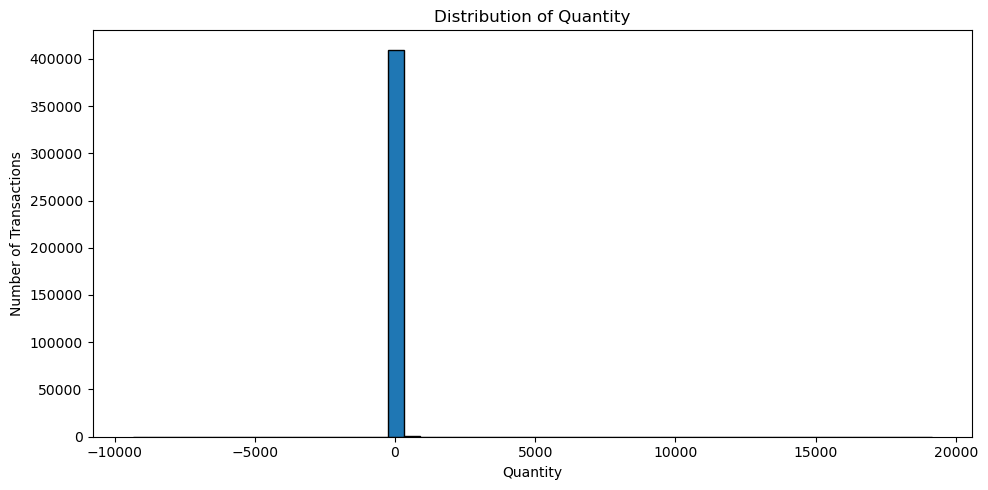

In [155]:
# How are Quantity distributed? Are most transactions small, or are there unusually large quantities and prices?
# Show the distributions using Histograms, bins =50, grouped into 50 interval to see distribution, figsize of 10 width inches and 5 height tall inches 
plt.figure(figsize=(10, 5))
plt.hist(df["Quantity"], bins=50, edgecolor="black")
plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

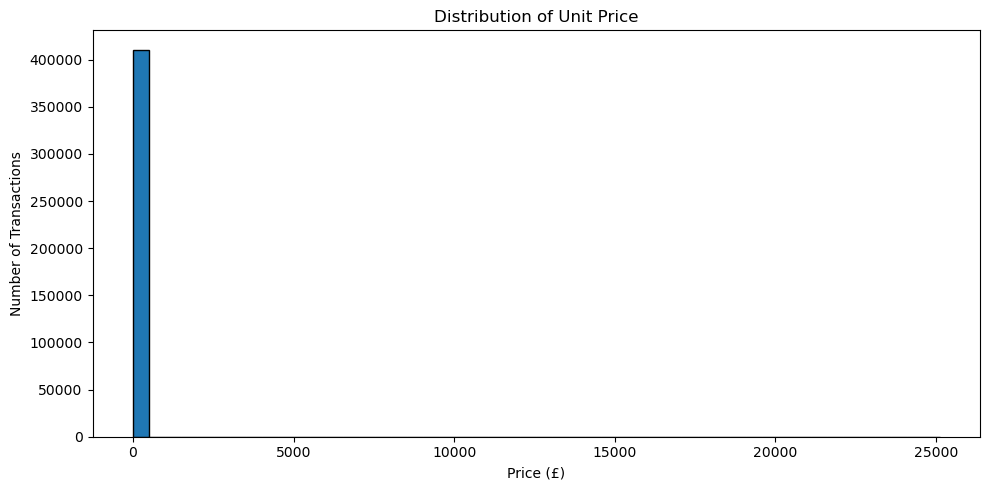

In [156]:
# How are price distributed? Are most transactions small, or are there unusually large quantities and prices?
# Show the distributions using Histograms, bins =50, grouped into 50 interval to see distribution, figsize of 10 width inches and 5 height tall inches

plt.figure(figsize=(10, 5))
plt.hist(df["Price"], bins=50, edgecolor="black")
plt.title("Distribution of Unit Price")
plt.xlabel("Price (£)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

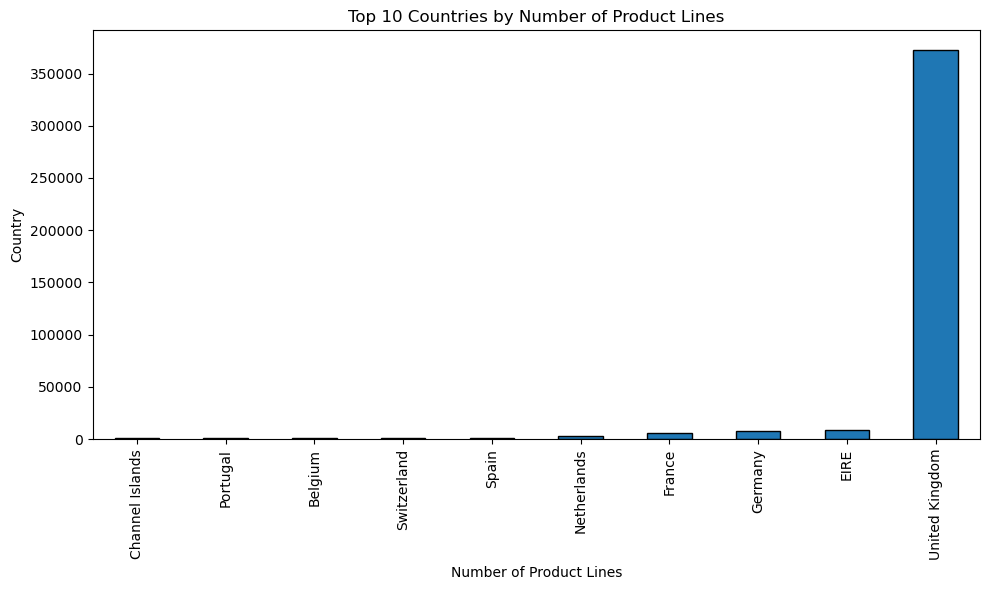

In [157]:
# Which countries have the most transactions?

top_countries = df["Country"].value_counts().head(10)

# 10 inches wide and 6 inches tall
plt.figure(figsize=(10, 6))
top_countries.sort_values().plot(kind="bar", edgecolor="black")

plt.title("Top 10 Countries by Number of Product Lines")
plt.xlabel("Number of Product Lines")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

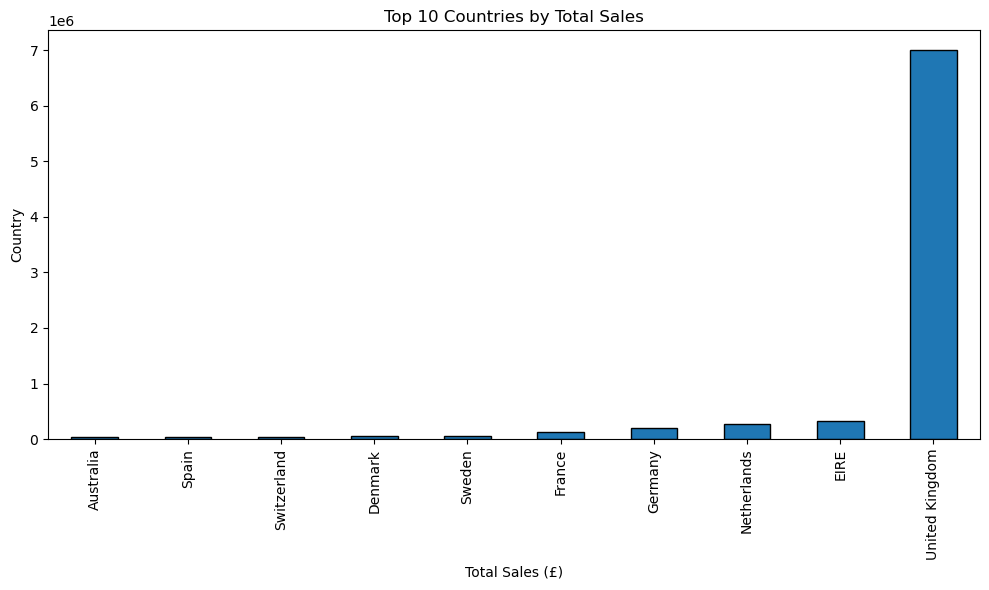

In [158]:
# groupby country and use sum sales =, wrapped inside country_sales
country_sales = df.groupby("Country")["Sales"].sum()

# sortvalue country sales, showe the top 10 in descending or highest order 
country_sales = country_sales.sort_values(ascending=False).head(10)

# 10 inches wide and  inches tall
plt.figure(figsize=(10, 6))

# bar plot 
country_sales.sort_values().plot(kind="bar", edgecolor="black")

plt.title("Top 10 Countries by Total Sales")
plt.xlabel("Total Sales (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

If we want to calculate how often a customer shops, counting rows would be misleading. A customer buying 10 different products in one invoice should not automatically count as having made 10 purchases. That's why we'll use invoice counts when calculating purchase frequency for RFM.
So finding the unique of each column is important for RFM

In [159]:
# How many transactions and customers are in the dataset? How many unique invoices and identified customers do we have after cleaning?

print("Total product lines:", len(df))  # show how many products
print("Unique invoices:", df["Invoice"].nunique()) # show how many unique invoices
print("Unique customers:", df["Customer ID"].nunique()) # show how many unique customer
print("Unique products:", df["StockCode"].nunique()) # show how many unique stock code

Total product lines: 410763
Unique invoices: 23587
Unique customers: 4383
Unique products: 4031


In [160]:
# How much does each customer spend?

print("Total sales (£):", df["Sales"].sum()) # total sum of sales column 
print("Average sales per product line (£):", df["Sales"].mean()) # means of the sales column
print("Median sales per product line (£):", df["Sales"].median())# median of sales column

Total sales (£): 8314855.584000001
Average sales per product line (£): 20.242464837387985
Median sales per product line (£): 11.8


In [161]:
# show the top 10 (group by customer id, total sum of sales, sort the value by highest order, wrapped it in a variable called top_customer)
top_customers = ( df.groupby("Customer ID")["Sales"].sum().sort_values(ascending=False).head(10))

# show top_customer variable
print(top_customers)

Customer ID
18102.0    341776.73
14646.0    243853.05
14156.0    183163.55
14911.0    137710.76
13694.0    128172.42
17511.0     83760.60
15061.0     82162.74
16684.0     75610.17
13089.0     55801.73
16754.0     54558.18
Name: Sales, dtype: float64


In [162]:
# show the top 10 (group by customer id and unique invoices then sort the values in highest order
customer_frequency = ( df.groupby("Customer ID")["Invoice"] .nunique().sort_values(ascending=False))


print("Top 10 customers by number of invoices:") # heading tittle
print(customer_frequency.head(10)) #show customer_frequency variable 

Top 10 customers by number of invoices:
Customer ID
14911.0    270
12748.0    159
17850.0    158
15311.0    158
14156.0    138
14606.0    135
13089.0    132
17841.0    126
14527.0    108
13694.0    105
Name: Invoice, dtype: int64


## Feature Engineering : Customer-Level RFM Analysis.

RFM analysis summarizes customer purchasing behaviour using three features:

-Recency: How recently a customer bought something.
-Frequency: How many times a customer purchased.
-Monetary: How much a customer spent in total.

These features will be used for K-Means clustering to identify groups of customers with similar purchasing behaviours.

To perform RFM analysis, we need to identify valid purchases. Cancellations and negative quantities can distort our Recency and Frequency calculations. However, we kept these records during data cleaning to preserve useful information. Therefore, we create a separate DataFrame called only_purchase_df for valid purchases without changing the original dataset.

In [163]:
# we created only_purchase_df variable here
# locate columns of invoice that their value row start with C and quanity greater than 0, then copy or save as a datafrane
only_purchase_df = df.loc[(~df["Invoice"].astype(str).str.startswith("C")) &(df["Quantity"] > 0)].copy()

print("Original rows:", len(df)) #lenght of originalfirst dataframe
print("Valid purchase rows:", len(only_purchase_df)) # lenght of our purchase_df var
print("Unique customers:", only_purchase_df["Customer ID"].nunique()) # unique customer in purchase_df dataframe

Original rows: 410763
Valid purchase rows: 400947
Unique customers: 4314


#### Recency

In [164]:
# we created analysis_date variable that contaain latest invoice date represeting eacch day (doing this coz of recency)
analysis_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

#show the variable analysis_variable
print("Analysis date:", analysis_date) 

#latest date in the invoice date
print("Latest invoice date:", df["InvoiceDate"].max())

Analysis date: 2010-12-10 20:01:00
Latest invoice date: 2010-12-09 20:01:00


In [165]:
# using only_purchase_df, group by customer id, latest invoice date using .max() and reset it as normal column instead of index using reset_index(), Store it in a variable called recency
recency = (only_purchase_df.groupby("Customer ID")["InvoiceDate"].max().reset_index())

#this code calculates how many days ago each customer last purchased something. 
recency["Recency"] = ( analysis_date - recency["InvoiceDate"]).dt.days

# Print recency, first 5
print(recency.head())

   Customer ID         InvoiceDate  Recency
0      12346.0 2010-06-28 13:53:00      165
1      12347.0 2010-12-07 14:57:00        3
2      12348.0 2010-09-27 14:59:00       74
3      12349.0 2010-10-28 08:23:00       43
4      12351.0 2010-11-29 15:23:00       11


#### Frequency

In [166]:
# using only_purchase_df, group by customer id, along with unique invoice and reset it as normal column instead of index using reset_index(),Names and save the column name as Frequency. Store it in a variable called frequency
frequency = (only_purchase_df.groupby("Customer ID")["Invoice"].nunique().reset_index(name="Frequency"))

#print frequeny, first 5 
print(frequency.head())

   Customer ID  Frequency
0      12346.0         11
1      12347.0          2
2      12348.0          1
3      12349.0          3
4      12351.0          1


#### Monetary

In [167]:
# using original df, group by customer id, and sum of sales on each (line 56), reset it as normal column instead of index using reset_index(),Names and save the column name as Monetary. Store it in a variable called Monetary
monetary = (df.groupby("Customer ID")["Sales"].sum().reset_index(name="Monetary"))

# show monetary first 5 
print(monetary.head())

   Customer ID  Monetary
0      12346.0    -51.74
1      12347.0   1323.32
2      12348.0    222.16
3      12349.0   2646.99
4      12351.0    300.93


##### Combine the all RFM data into a single merged Dataframe

In [168]:
# merging all the rfm together using customer id as identifier key in merging
rfm = recency[["Customer ID", "Recency"]].merge( frequency, on="Customer ID").merge( monetary,on="Customer ID")

In [169]:
# show the first 5 of or new rfrm df we just created 
rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346.0,165,11,-51.74
1,12347.0,3,2,1323.32
2,12348.0,74,1,222.16
3,12349.0,43,3,2646.99
4,12351.0,11,1,300.93


In [170]:
# show the shape, we have 4,314 row and 4 column 
rfm.shape

(4314, 4)

In [171]:
# statistics on rfm for scaling purposes
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,4314.000000,4314.000000,4314.000000
mean,91.269124,4.454103,1941.925604
std,96.943482,8.168658,8568.067496
min,1.000000,1.000000,-10953.500000
25%,18.000000,1.000000,296.077500
50%,53.000000,2.000000,670.160000
75%,136.000000,5.000000,1663.572500
max,374.000000,205.000000,341776.730000


In [172]:
# checking any negative monetary value coz scaler wont process it well, if sone row contain 0 or minus (the statistics reveal this issues)
print("Negative Monetary values:", (rfm["Monetary"] < 0).sum())
print("Zero Monetary values:", (rfm["Monetary"] == 0).sum())

Negative Monetary values: 21
Zero Monetary values: 10


In [173]:
# copying rfm into rfm_full_money with changes in monetary column, (fixing the negative value in monetary col) 
rfm_full_money = rfm[rfm["Monetary"] > 0].copy()

print("Original customers:", len(rfm)) #lenght of normal rfrm row 4,312
print("Customers for clustering:", len(rfm_full_money)) #lenght of the new var rfrm_full_money  4,283
print("Remaining non-positive Monetary values:",(rfm_full_money["Monetary"] <= 0).sum())  # validation and confirming any negative value (return 0)

Original customers: 4314
Customers for clustering: 4283
Remaining non-positive Monetary values: 0


In [174]:
# checking the skew distribution  ( they are still highky skewed and we might need to transform it)
rfm_full_money[["Recency", "Frequency", "Monetary"]].skew()

Recency       1.290198
Frequency    10.526922
Monetary     24.601566
dtype: float64

## Preprocessing and Feature Scaling.

We cannot do feature scalling without making sure all features in rfm are evenly or fairly skew in order to get good result for Scaling, so we will transform while preprocessing using pipeline

In [175]:
# we are going to be using PowerTransformer to transform the highly skewed features
from sklearn.preprocessing import PowerTransformer

# We will handle both at once with pipeline
from sklearn.pipeline import Pipeline

# we are going to be using PowerTransformer to transform and Scaler
from sklearn.preprocessing import PowerTransformer, StandardScaler


In [176]:
# handling both here and put it in a variable called preprocessor
preprocessor = Pipeline([("transformer", PowerTransformer(method="yeo-johnson", standardize=False)),
                        ("scaler", StandardScaler())])

In [177]:
# bringing out the 3 rfm into a varibale called rfm_features
rfm_features = ["Recency", "Frequency", "Monetary"]

#the feature scaling is happening here
X_scaled = preprocessor.fit_transform(rfm_full_money[rfm_features])

# confirm by showing the shape 
print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (4283, 3)


## K-Means Clustering: Model Training

In [178]:
# importing the K means clustering algorithm model
from sklearn.cluster import KMeans

In [179]:

#created model that identify  4 customer group,keep random same resul for each output and with ten initializations and keeps the best result.
k_means = KMeans(n_clusters=4, random_state=42, n_init=10)

#learns the clusters and assigns each customer a cluster number usimg k_meand we created earlier
clusters = k_means.fit_predict(X_scaled)

In [180]:
#confirming cluster shape
clusters.shape # confirming cluster shape

(4283,)

In [181]:
 #show cluster value in table after value count with indexing
(pd.Series(clusters).value_counts().sort_index())

0    1034
1    1053
2    1205
3     991
Name: count, dtype: int64


K-Means model has assigned all 4,283 customers to four clusters.
    
Cluster	Customers

0	1,034
1	1,053
2	1,205
3	  991

Total 4,283

## Choosing the Optimal Number of Clusters

Determine the most suitable number of customer groups (K) using inertia and the Silhouette Score.

#### Insertia

In [182]:
# Test different numbers of clusters, from 1 to 10
for k in range(1, 11):
    # Create a K-Means model using k clusters
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    # Train the model using our scaled customer data
    model.fit(X_scaled)
     # Print the number of clusters and its inertia score
    print(f"K={k}, Inertia={model.inertia_:.2f}")

K=1, Inertia=12849.00
K=2, Inertia=6271.74
K=3, Inertia=4810.87
K=4, Inertia=3755.21
K=5, Inertia=3183.30
K=6, Inertia=2782.45
K=7, Inertia=2527.86
K=8, Inertia=2309.34
K=9, Inertia=2145.89
K=10, Inertia=1997.60


Interpreting Inertia output

Inertia measures how close customers are to their assigned cluster centres. Lower inertia means customers are grouped more closely together.

As the number of clusters (K) increases, inertia decreases because customers are divided into more groups. However, adding more clusters makes the model more complex.

The goal is to identify a suitable K where the reduction in inertia begins to slow down noticeably. This is known as the Elbow Point.

Observation: In our results, inertia drops sharply from K=1 to K=2, then the reductions gradually become smaller. This suggests that a reasonable number of clusters may lie around K=3 to K=5, but we will use the Silhouette Score to help make the final decision.

#### Silhouette Score

In [183]:
# importing silhouette_score lib
from sklearn.metrics import silhouette_score

In [ ]:
# Test cluster numbers from 2 to 6
for k in range(2, 7):
    # Create a K-Means model with k clusters
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    # Train the model and assign each customer to a cluster
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    # Print the silhouette score to four decimal places
    print(f"K={k}, Silhouette Score={score:.4f}")

K=2, Silhouette Score=0.4224
K=3, Silhouette Score=0.3258


##### Silhouette Score Results

K=2 achieved the highest Silhouette Score of 0.4224, indicating better-separated clusters than the other tested values. However, the best score alone does not guarantee the most useful business segments, so we will also consider cluster interpretability and business value before making the final decision.

## Cluster Evaluation and Visualization

The K-Means model with K=2 identified two customer segments with distinct purchasing behaviours based on Recency, Frequency, and Monetary values.

In [ ]:
# Train the selected K=2 model and assign cluster labels
k_means = KMeans(n_clusters=2, random_state=42, n_init=10)
rfm_full_money["Cluster"] = k_means.fit_predict(X_scaled)

# Summarise each cluster using average RFM values
cluster_profile = rfm_full_money.groupby("Cluster").agg({ "Recency": "mean", "Frequency": "mean", "Monetary": "mean"}).round(2)

print(cluster_profile)

Findings: K-Means identified two distinct customer segments. Cluster 0 contains more recently active, frequent, higher-spending customers, while Cluster 1 contains less recently active, infrequent, lower-spending customers.

## Customer Segment Profiling and Business Insights.

In [ ]:
# Count customers in each cluster
print(rfm_full_money["Cluster"].value_counts().sort_index())

**Customer Distribution:** Cluster 0 contains 2,036 customers, while Cluster 1 contains 2,247 customers. Cluster 1 is slightly larger, but customer value and purchasing behaviour must also be considered when developing marketing strategies.

In [ ]:
# Calculate median RFM values for each cluster
cluster_medians = rfm_full_money.groupby("Cluster").agg({ "Recency": "median", "Frequency": "median", "Monetary": "median"})

print(cluster_medians)

**Segment Insights:** Cluster 0 represents more recently active, frequent, higher-spending customers. Cluster 1 represents less recently active, infrequent, lower-spending customers. Median RFM values support the distinction between these segments while reducing the influence of extreme values.

## Business Recommendations and Customer Strategies

- **Cluster 0:** Focus on customer retention, loyalty rewards, and repeat purchases.
- **Cluster 1:** Focus on re-engagement campaigns, personalised recommendations, and incentives to encourage repeat purchases.

Cluster 0 — High-value, engaged customers
2,036 customers · Median spend: £1,709.31
- Reward loyalty with exclusive offers or early access to new products.
- Encourage repeat purchases through personalised recommendations.
- Focus on retention to maintain their engagement.
  
  Cluster 1 — Lower-engagement customers
  2,247 customers · Median spend: £311.78
- Send targeted re-engagement offers to encourage another purchase.
- Recommend products based on their previous purchases.
- Test reminders or incentives to see what brings customers back.

##### Identifying customers in each cluster using their Customer ID

Find the actual customers in Cluster 0

In [ ]:
# Retrieve customer IDs assigned to Cluster 0 through filtering
cluster_0_customers = rfm_full_money[rfm_full_money["Cluster"] == 0]

print(cluster_0_customers.head(10))

Find customers in Cluster 1

In [ ]:
# Retrieve customer IDs assigned to Cluster 1 through filtering
cluster_1_customers = rfm_full_money[ rfm_full_money["Cluster"] == 1]

print(cluster_1_customers.head(10))

## Final Model and New Predictions

In [ ]:
# Check the final model and preprocessing pipeline
# Here we trying to check the kind of feature engineering we had use earlier to preprocess for new data and predictions
print("Preprocessing pipeline:", preprocessor)
print("K-Means clusters:", k_means.n_clusters)
print("Features used:", rfm_features)

In [ ]:
# Example: a new customer's RFM values
new_customer = pd.DataFrame({ "Recency": [20], "Frequency": [6], "Monetary": [2000]})

# Apply the existing preprocessing pipeline (using rfrm_feature) preserved for testing and new predictions
new_customer_scaled = preprocessor.transform(new_customer[rfm_features])

# Predict the customer's cluster
predicted_cluster = k_means.predict(new_customer_scaled)

print("Predicted customer cluster:", predicted_cluster[0])

Retrieves the median Recency, Frequency, and Monetary values for the predicted segment, helping us to interpret the assignment using the existing results

In [ ]:
print("Customer's predicted cluster:", predicted_cluster[0])
print("\nMedian RFM profile for this cluster:")
print(cluster_medians.loc[predicted_cluster[0]])

## Model Saving and Deployment.

In [ ]:
import joblib

# Save the preprocessing pipeline and trained model together
joblib.dump( {"preprocessor": preprocessor, "model": k_means, "features": rfm_features }, "customer_segmentation_model.pkl")

print("Model and preprocessing pipeline saved.")

## Conclusion and Key Findings


This project used unsupervised machine learning to identify customer segments from the UCI Online Retail II dataset. Recency, Frequency, and Monetary (RFM) features were engineered to represent customer purchasing behaviour.

The RFM features were transformed using a Yeo-Johnson transformation and standardised before applying K-Means clustering. The Silhouette Score was used alongside inertia to compare different cluster counts, and **K=2** was selected for the final model.

The model identified two distinct customer segments:

- **Cluster 0 — Active, Higher-Value Customers:** 2,036 customers, with median Recency of 22 days, median Frequency of 5 orders, and median Monetary value of £1,709.31.
- **Cluster 1 — Less Active, Lower-Value Customers:** 2,247 customers, with median Recency of 112 days, median Frequency of 1 order, and median Monetary value of £311.78.

The findings suggest that the business could focus on customer retention and loyalty initiatives for Cluster 0, while using targeted re-engagement campaigns to encourage repeat purchases among Cluster 1 customers.

Finally, the fitted preprocessing pipeline and K-Means model were saved in `customer_segmentation_model.pkl` for reuse when assigning new customers to a segment.

**Limitation:** These segments are based on historical transactions from the dataset's available period. The recommendations are proposed strategies, and their effectiveness would need to be tested using actual campaign results.